# 3. Galactic binaries: LISA and a detector network

**Goal:** initialise a detector network, inject one source, and compare
LISA with **LISA + Taiji + TianQin**.
**Zero-noise injection:** $d=h(\lambda_0,\beta_0)$; no random noise is added.

Only ecliptic longitude $\lambda$ and latitude $\beta$ vary, and they vary over
the **whole sky** under an isotropic prior; the other six source parameters stay
fixed. This is therefore a two-parameter conditional sky posterior, not a fully
marginalised one. 

In [1]:
%matplotlib inline
# Paths and plotting defaults only; the scientific workflow is below.
from tutorial_tools.common import DATA, OUTPUT, ORBIT, DAY, load_arrays, inner
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Parallel sampling, as in the Triangle-GB network example: the "fork" start
# method lets the notebook-defined likelihood class reach the worker processes.
import multiprocessing
if multiprocessing.get_start_method(allow_none=True) != "fork":
    multiprocessing.set_start_method("fork", force=True)
NPROC = multiprocessing.cpu_count()
print("CPU cores:", NPROC, "| start method:", multiprocessing.get_start_method())


CPU cores: 12 | start method: fork


## 1. Initialise the detector orbits and noise models

In [2]:
from Triangle.Constants import YEAR
from Triangle.Orbit import HeliocentricEqualArmAnalyticOrbit, GeocentricEqualArmAnalyticOrbit
from Triangle.Noise import TDIPSDs

missions = ["LISA", "Taiji", "TianQin"]
orbits = [
    HeliocentricEqualArmAnalyticOrbit(L=2.5e9, kap=-np.deg2rad(40), lam=0.12801155,
                                    dt=DAY, Tobs=2*YEAR, pn_order=0),
    HeliocentricEqualArmAnalyticOrbit(L=3e9, kap=0., lam=6.10414095,
                                    dt=DAY, Tobs=2*YEAR, pn_order=0),
    GeocentricEqualArmAnalyticOrbit(L=np.sqrt(3)*1e8, kappa0=1.22975531,
                                   kappa_earth=-np.deg2rad(20), dt=6000.,
                                   Tobs=2*YEAR, pn_order=0)]
noise_models = [TDIPSDs(L=2.5e9, sacc=3e-15, sro=15e-12),
                TDIPSDs(L=3e9, sacc=3e-15, sro=8e-12),
                TDIPSDs(L=np.sqrt(3)*1e8, sacc=1e-15, sro=1e-12)]

PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


No pyseobnr.
no cupy 


## 2. Initialise the waveform and TDI response

In [3]:
from Triangle.TDI import TDIStringManipulation
from Triangle_GB.TDIFly import TDIFly, TDIFlyGBNetwork

T, dt = int(YEAR/20)*20., 20.
X = TDIFly.X2_strings
Y = TDIStringManipulation.TDIStringCyc(X)
Z = TDIStringManipulation.TDIStringCyc(Y)
generator = TDIFlyGBNetwork(orbits, [X, Y, Z], np.arange(int(T/dt))*dt,
                           Nsparse=2048, use_gpu=False)
center = round(0.003*T)
bins = np.arange(center-510, center+511)
f, fdot = bins/T, 2e-17
p = dict(A=1e-22, f0=(center-0.5*fdot*T**2)/T, fdot0=fdot,
         inclination=1.1, longitude=4.5, latitude=-0.3, phase0=0.8, psi=0.7)

def network_waveform(parameters):
    return np.asarray(generator.response_on_band(parameters, int(bins[0]), int(bins[-1])))

no cupy 


## 3. Make a zero-noise injection and check SNR

In [4]:
psd = np.array([model.PSD_A2(f) for model in noise_models for channel in ("A", "E")])
weight = 4/T/psd
h = network_waveform(p)[:, 0]
initial_snr = np.sqrt(np.sum(abs(h[:2])**2*weight[:2]))
p['A'] *= 30/initial_snr
h = network_waveform(p)[:, 0]
data = h.copy()
sky0 = np.array([p["longitude"], p["latitude"]])
snrs = np.sqrt(np.sum((abs(h)**2*weight).reshape(3, 2, -1), axis=(1, 2)))
print("SNR per mission:", dict(zip(missions, snrs)))
print("Network SNR:", np.linalg.norm(snrs))
print("Injected (lambda, beta) [rad]:", sky0)
np.testing.assert_allclose(snrs[0], 30, rtol=1e-10)
assert np.array_equal(data, h)

SNR per mission: {'LISA': 29.999999999999996, 'Taiji': 44.33604383511101, 'TianQin': 9.04547980096605}
Network SNR: 54.29093375305467
Injected (lambda, beta) [rad]: [ 4.5 -0.3]


## 4. Write the sky likelihood

In [5]:
def sky_loglike(sky, channels):
    sky = np.atleast_2d(sky)
    values = []
    for i in range(0, len(sky), 8):
        points = sky[i:i+8]
        parameters = {k: np.full(len(points), v) for k, v in p.items()}
        parameters.update(longitude=points[:, 0], latitude=points[:, 1])
        r = data[:channels, None, :]-network_waveform(parameters)[:channels]
        values.extend(-0.5*np.sum(abs(r)**2*weight[:channels, None, :], axis=(0, 2)))
    return np.asarray(values)

np.testing.assert_allclose(sky_loglike(sky0, 6), 0, atol=1e-12)
for channels in (2, 6):
    print(channels, "channels: log L at displaced sky =",
          sky_loglike(sky0+[0.002, 0.002], channels)[0])

2 channels: log L at displaced sky = -0.0707851422160019
6 channels: log L at displaced sky = -0.23385662985454636


## 5. Full-sky prior, and the sampler
Nothing is localised by hand here: the prior is the isotropic sky prior of the
Triangle-GB network example, applied to the whole sphere,
$p(\lambda,\beta)\propto\cos\beta$ over $\lambda\in[0,2\pi)$ and
$\beta\in[-\pi/2,\pi/2]$. No Fisher matrix is computed or used, so the sampled
region is not tailored to the injection — every mode that exists over the full
sky is a mode the plot can show.

Sampling follows the example: `bilby.run_sampler(sampler="nessai",
nlive=1000, stopping=0.1, n_pool=cpu_count())` once per detector selection,
with the same seed for both runs.


### Set the sky priors explicitly
Two parameters are sampled and six are held at their injected values, so the
prior alone defines the search region. It is the full sky, in the same forms as
the Triangle-GB network example.

| parameter | prior | range |
|---|---|---|
| $\lambda$ | bilby `Uniform`, `boundary="periodic"` | $[0,\,2\pi)$ |
| $\beta$ | bilby `Cosine` | $[-\pi/2,\,\pi/2]$, $p\propto\cos\beta$ |


In [6]:
import bilby

# Full-sky prior: isotropic on the sphere, uniform and periodic in longitude.
sky_priors = bilby.core.prior.PriorDict()
sky_priors["longitude"] = bilby.prior.Uniform(0., 2*np.pi, name="longitude",
                                              boundary="periodic")
sky_priors["latitude"] = bilby.prior.Cosine(-np.pi/2., np.pi/2.,
                                            name="latitude")
print(sky_priors)

class SkyLikelihood(bilby.Likelihood):
    """bilby wrapper: only longitude and latitude vary, everything else fixed."""
    def __init__(self, channels):
        super().__init__(parameters={"longitude": None, "latitude": None})
        self.channels = channels

    def log_likelihood(self):
        point = [[self.parameters["longitude"], self.parameters["latitude"]]]
        return float(sky_loglike(point, self.channels)[0])

for channels in (2, 6):
    like = SkyLikelihood(channels)
    like.parameters.update(dict(zip(("longitude", "latitude"), sky0)))
    print(channels, "channels: log L at injection =", like.log_likelihood())


{'longitude': Uniform(minimum=0.0, maximum=6.283185307179586, name='longitude', latex_label='longitude', unit=None, boundary='periodic'), 'latitude': Cosine(minimum=-1.5707963267948966, maximum=1.5707963267948966, name='latitude', latex_label='latitude', unit=None, boundary=None)}
2 channels: log L at injection = -0.0
6 channels: log L at injection = -0.0


## 6. Sample the sky posterior with nessai
Both detector selections are sampled with nessai through bilby: a normalising
flow is trained on the two-parameter posterior and integrated by nested
sampling, with the priors above, the same seed for both runs and one worker per
CPU core. Files go to `outputs/gb_network_nessai/`; nessai reuses them when the
cell is re-run, so delete that folder to force fresh sampling.

Each run reports the number of draws, the posterior mean, the 1-sigma widths and
the log-evidence. The mean should land on the injection and the widths shrink
when Taiji and TianQin are added; because the posterior is a single mode here,
those widths are the localisation error itself.


In [7]:
import time

results, draws = {}, {}
start_clock = time.perf_counter()
for label, channels in (("lisa", 2), ("network", 6)):
    run_start = time.perf_counter()
    results[label] = bilby.run_sampler(
        likelihood=SkyLikelihood(channels), priors=sky_priors, sampler="nessai",
        nlive=1000, stopping=0.1, n_pool=NPROC, pytorch_threads=1,
        seed=20261121, outdir=str(OUTPUT/"gb_network_nessai"), label=label,
        resume=False, plot=False)
    draws[label] = results[label].posterior[["longitude", "latitude"]].to_numpy()
    mean, sigma = draws[label].mean(axis=0), draws[label].std(axis=0)
    print(f"{channels} channels: {len(draws[label])} draws in "
          f"{time.perf_counter()-run_start:.0f} s | mean = "
          f"({mean[0]:.4f}, {mean[1]:.4f}) rad | 1 sigma = "
          f"({sigma[0]:.4f}, {sigma[1]:.4f}) rad", flush=True)
print("Total sampling time [s]:", round(time.perf_counter()-start_clock, 1))


13:23 bilby INFO    : Running for label 'lisa', output will be saved to '/Users/taijidatacenter/Desktop/PTASchool/Du_Minghui_Lecture/student_tutorials/outputs/gb_network_nessai'
/Users/taijidatacenter/miniconda3/envs/tri_env/lib/python3.9/site-packages/bilby/core/utils/log.py:73: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  vdict[key] = str(getattr(sys.modules[key], "__version__", "N/A"))
13:23 bilby INFO    : Analysis priors:
13:23 bilby INFO    : longitude=Uniform(minimum=0.0, maximum=6.283185307179586, name='longitude', latex_label='longitude', unit=None, boundary='periodic')
13:23 bilby INFO    : latitude=Cosine(minimum=-1.5707963267948966, maximum=1.5707963267948966, name='latitude', latex_label='latitude', unit=None, boundary=None)
13:23 bilby INFO    : Analysis likelihood class: <class '__main__.SkyLikelihood'>
13:23 bilby INFO    : Analysis likelihoo

2 channels: 2670 draws in 4 s | mean = (4.5000, -0.2991) rad | 1 sigma = (0.0063, 0.0142) rad


13:23 bilby INFO    : Running for label 'network', output will be saved to '/Users/taijidatacenter/Desktop/PTASchool/Du_Minghui_Lecture/student_tutorials/outputs/gb_network_nessai'
/Users/taijidatacenter/miniconda3/envs/tri_env/lib/python3.9/site-packages/bilby/core/utils/log.py:73: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  vdict[key] = str(getattr(sys.modules[key], "__version__", "N/A"))
13:23 bilby INFO    : Analysis priors:
13:23 bilby INFO    : longitude=Uniform(minimum=0.0, maximum=6.283185307179586, name='longitude', latex_label='longitude', unit=None, boundary='periodic')
13:23 bilby INFO    : latitude=Cosine(minimum=-1.5707963267948966, maximum=1.5707963267948966, name='latitude', latex_label='latitude', unit=None, boundary=None)
13:23 bilby INFO    : Analysis likelihood class: <class '__main__.SkyLikelihood'>
13:23 bilby INFO    : Analysis likeli

6 channels: 2606 draws in 3 s | mean = (4.5000, -0.2995) rad | 1 sigma = (0.0034, 0.0076) rad
Total sampling time [s]: 7.0


## 7. Compare the sampled posteriors

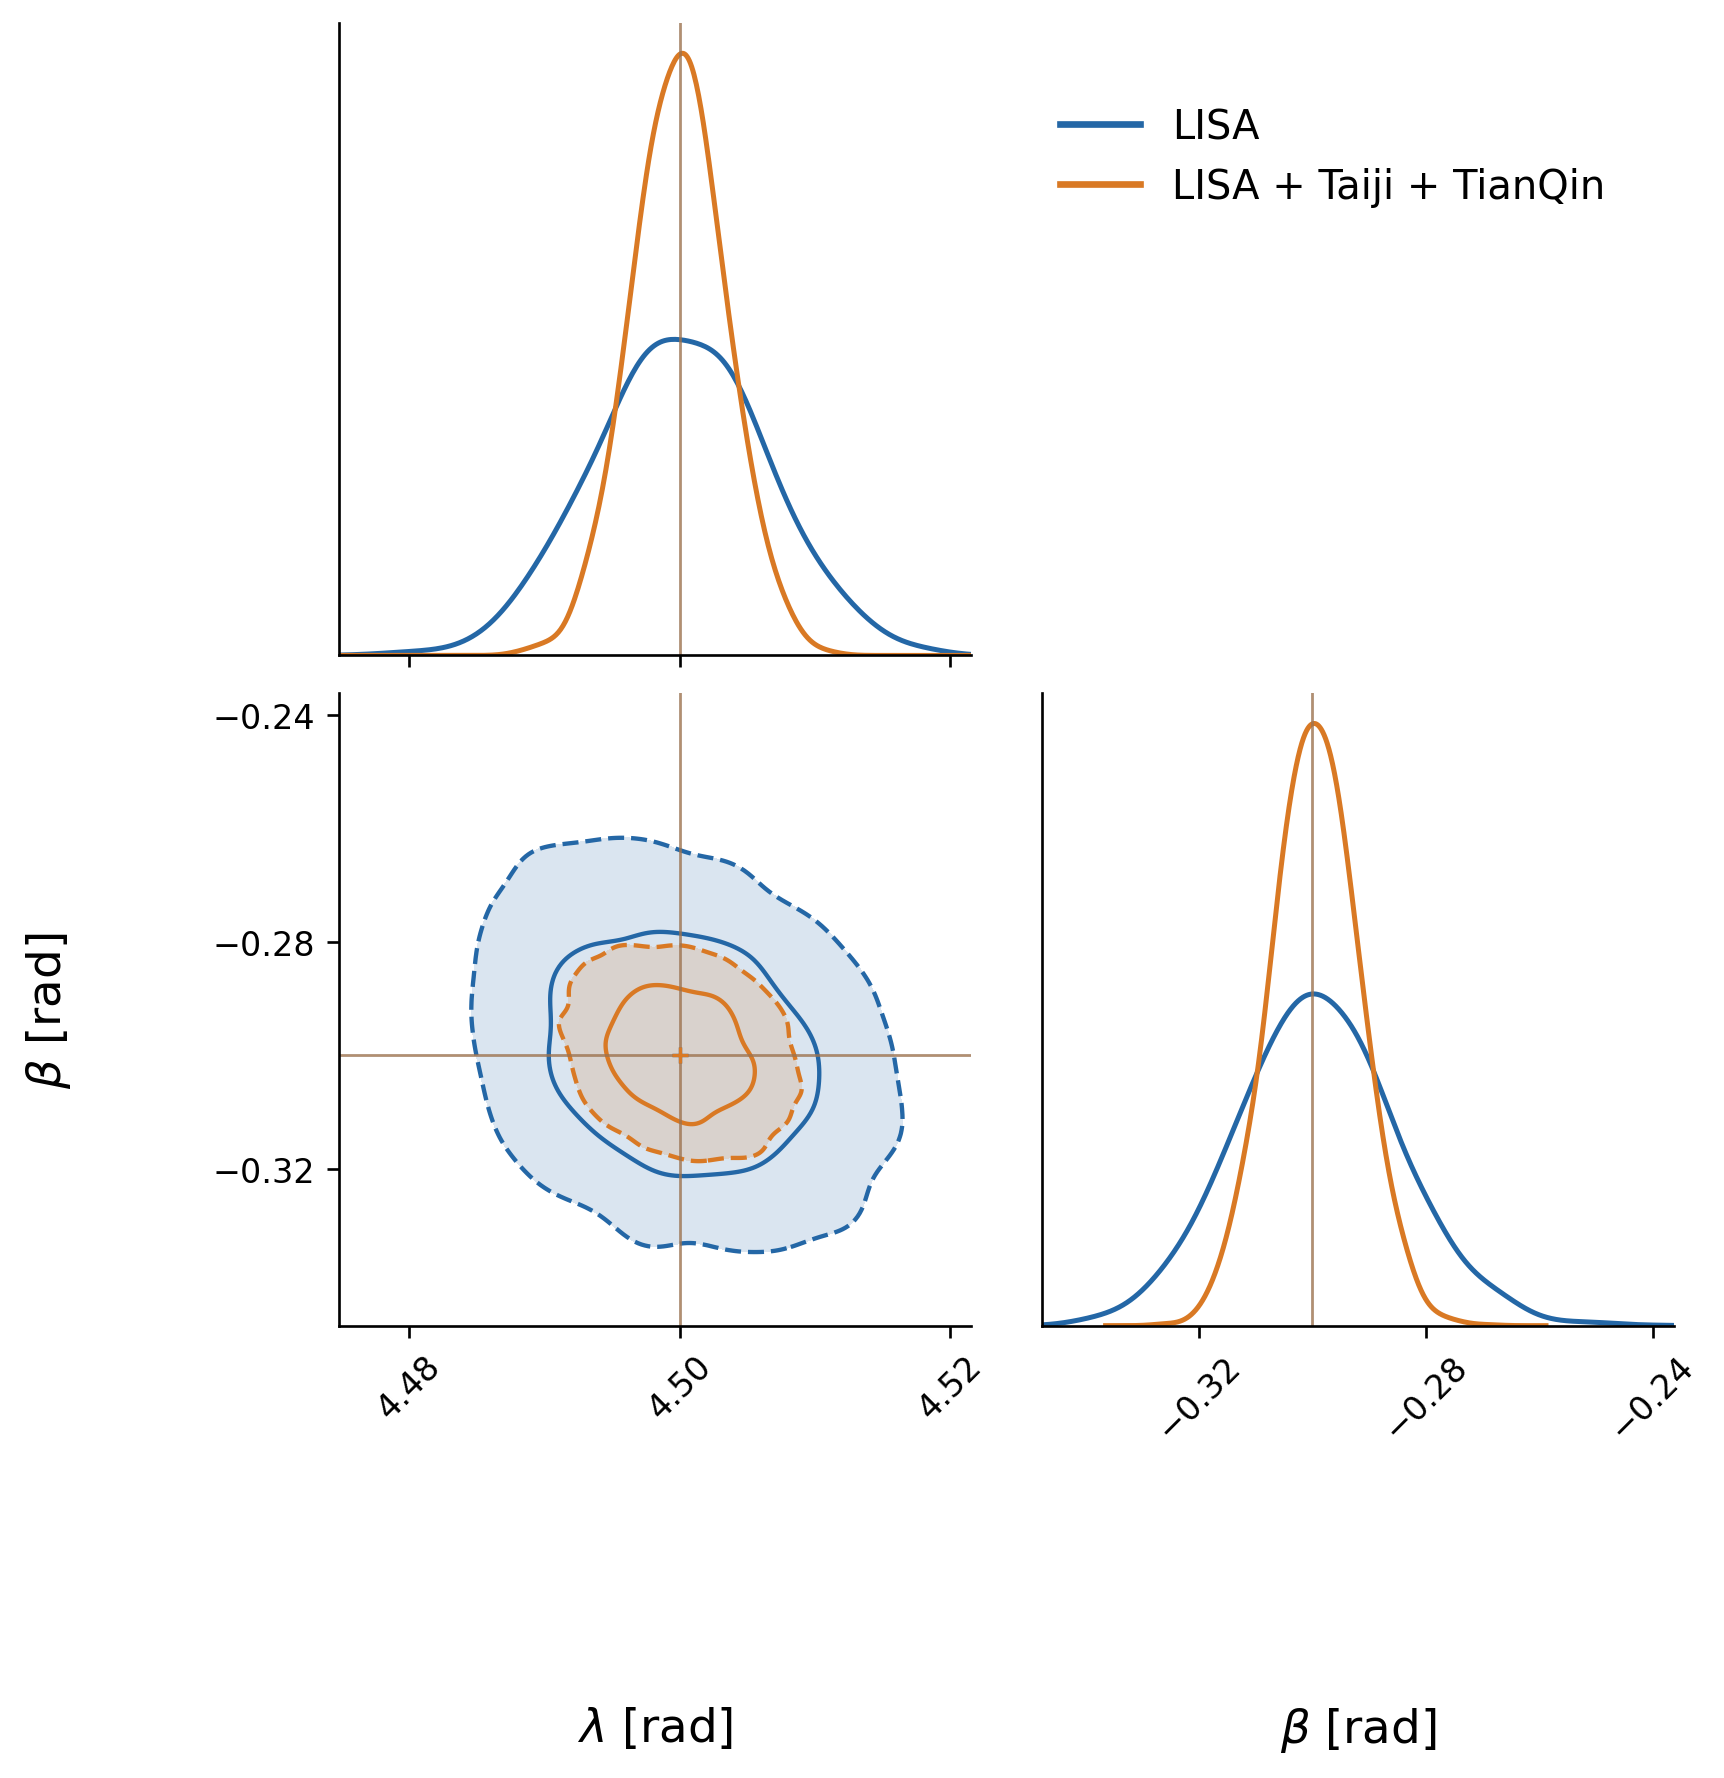

In [8]:
from tutorial_tools.corners import corner_plot

# The same kernel-density renderer as notebook 02, now on two axes that need
# special care: longitude is periodic and latitude is bounded.
corner_plot([draws["lisa"], draws["network"]],
            labels=[r"$\lambda$ [rad]", r"$\beta$ [rad]"],
            path=OUTPUT/"gb_network_posterior.png", truths=None,
            truth_sets=[sky0, sky0], colors=["#2467A6", "#D97924"],
            legend=["LISA", "LISA + Taiji + TianQin"],
            periods={0: 2*np.pi}, bounds={1: (-np.pi/2, np.pi/2)})
display(Image(filename=str(OUTPUT/"gb_network_posterior.png"), width=720))
np.savez_compressed(OUTPUT/"gb_network_sky_posterior.npz",
                    injection_frequency_Hz=f, injection_data=data, nominal_psd=psd,
                    lisa_draws=draws["lisa"], network_draws=draws["network"])


**Try:** set `bandwidth=0.05` in the corner cell and the contours break up into
the discrete draws — that is how much of the smoothness is the kernel rather
than the data. Then raise `nlive` or tighten `stopping` and check whether the
contours move; change the sky position or duration, then regenerate both data
and posteriors. Finally, make the other six parameters free: competing sky modes
appear, and `bandwidth` then has to be small enough not to merge them.

**Sources:** `Triangle-GB/Examples/GB_network_PE_example_for_2609.16477.ipynb`.
[Repository](https://github.com/TriangleDataCenter/Triangle-GB).
